In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stat
import warnings
warnings.filterwarnings('ignore')

In [129]:
df = pd.read_csv("heart.csv")

In [130]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [131]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [132]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [133]:
df.shape

(918, 12)

In [134]:
numeric_col = df.select_dtypes(include= 'number').columns.tolist()

In [135]:
numeric_col

['Age',
 'RestingBP',
 'Cholesterol',
 'FastingBS',
 'MaxHR',
 'Oldpeak',
 'HeartDisease']

<Axes: xlabel='HeartDisease'>

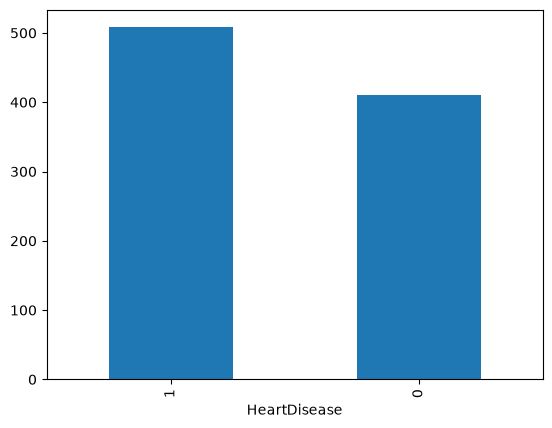

In [136]:
df['HeartDisease'].value_counts().plot(kind='bar')

In [137]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

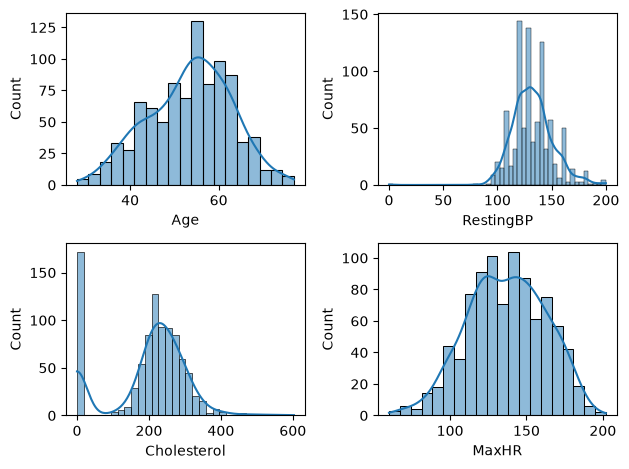

In [138]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde=True)

plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)

plt.tight_layout()

In [139]:
ch_mean = df.loc[df['Cholesterol']!= 0,'Cholesterol'].mean()

In [140]:
ch_mean

np.float64(244.6353887399464)

In [141]:
df['Cholesterol'] = df['Cholesterol'].replace(0,ch_mean)
df['Cholesterol'] = df['Cholesterol'].round(2)

In [142]:
resting_bp_mean = df.loc[df['RestingBP']!= 0 , 'RestingBP'].mean()


In [143]:
df['RestingBP']=df['RestingBP'].replace(0,resting_bp_mean)
df['RestingBP'] =df['RestingBP'].round(2)

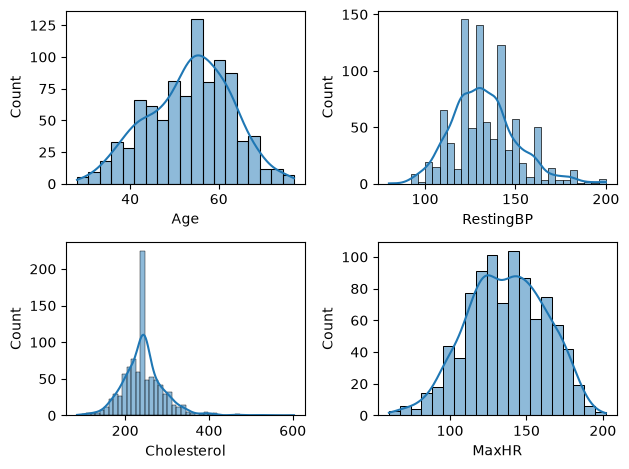

In [144]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde=True)

plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)

plt.tight_layout()

In [145]:
categoric_col = df.select_dtypes(include='str').columns.tolist()

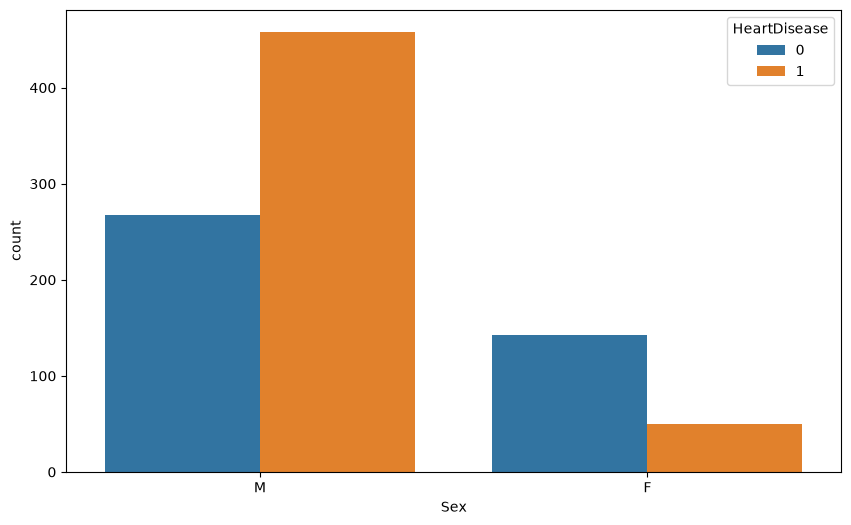

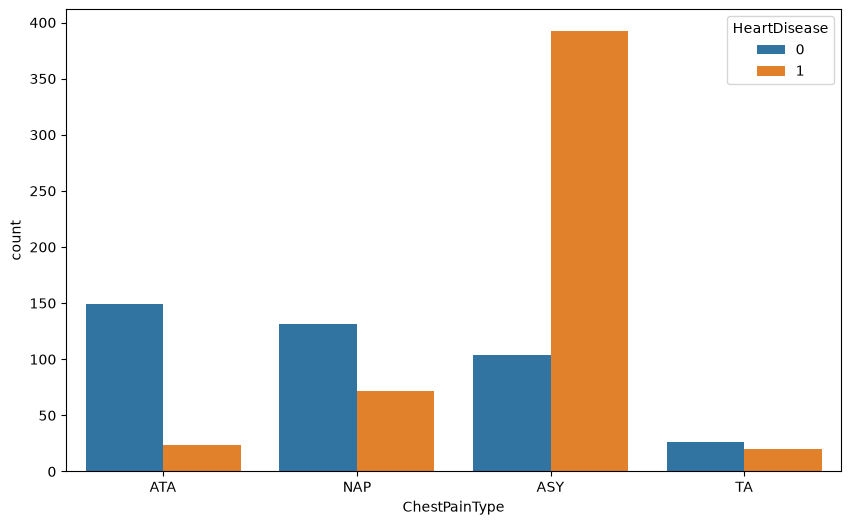

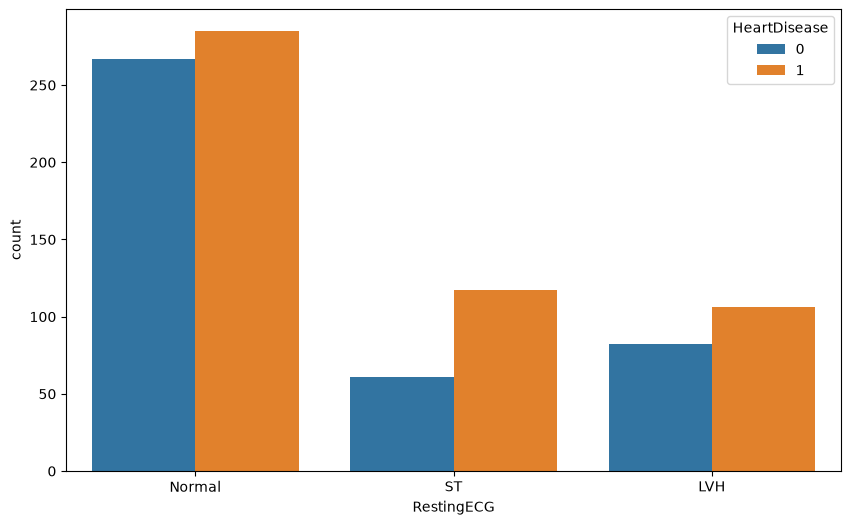

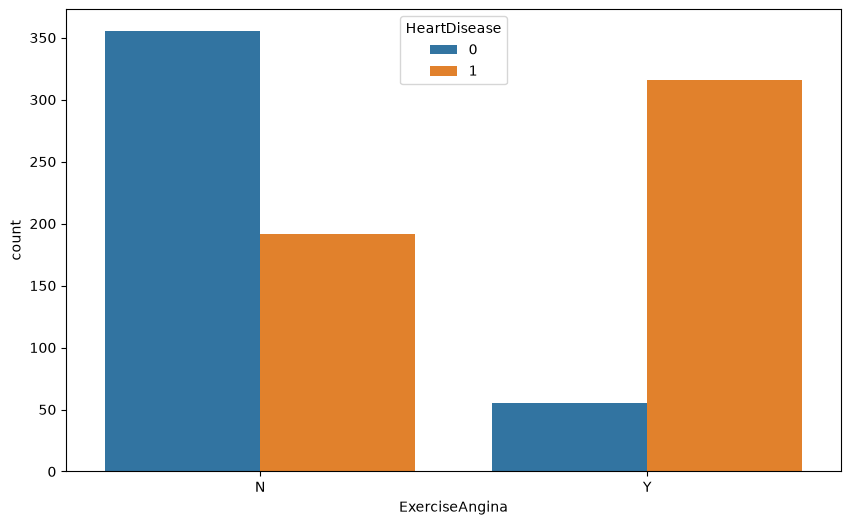

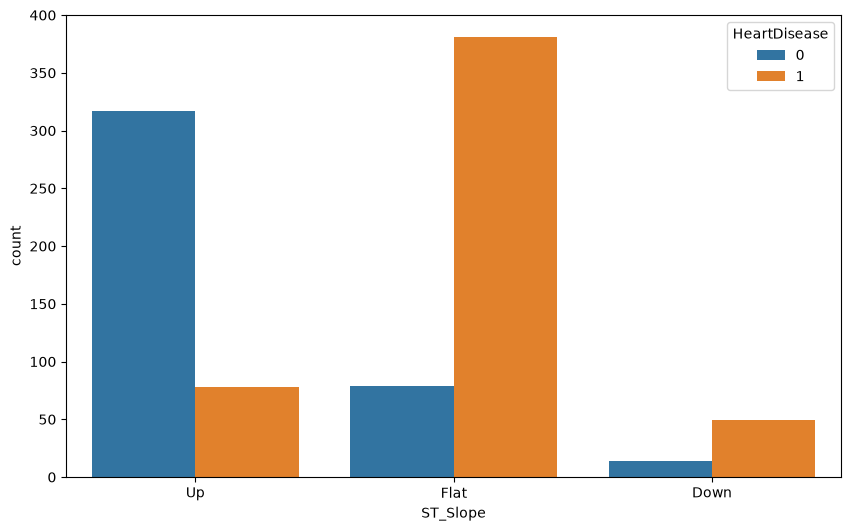

In [146]:
for col in categoric_col:
    plt.figure(figsize=(10,6))

    sns.countplot(data=df,x=col,hue=df['HeartDisease'])
    plt.show()

<Axes: >

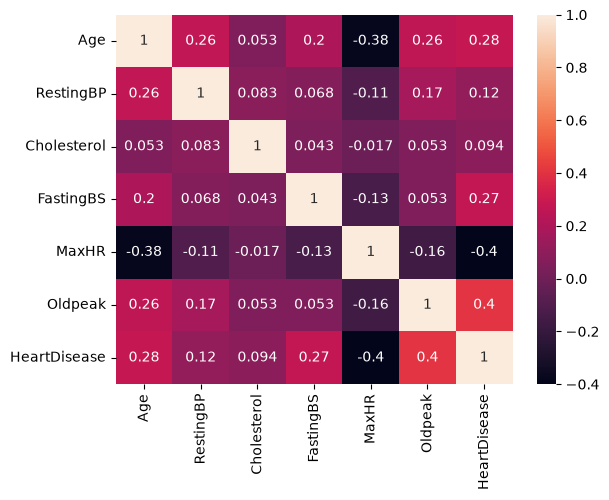

In [147]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [148]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0



Data Preprocessing 



In [149]:
df_encode = pd.get_dummies(df,drop_first=True)

In [150]:
df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160.0,180.0,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130.0,283.0,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138.0,214.0,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150.0,195.0,0,122,0.0,0,True,False,True,False,True,False,False,False,True


In [151]:
df_encode=df_encode.astype(int)

In [152]:
df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0,0,1,1,0,0,1,0,0,0,1
1,49,160,180,0,156,1,1,0,0,1,0,1,0,0,1,0
2,37,130,283,0,98,0,0,1,1,0,0,0,1,0,0,1
3,48,138,214,0,108,1,1,0,0,0,0,1,0,1,1,0
4,54,150,195,0,122,0,0,1,0,1,0,1,0,0,0,1


In [153]:
from scipy.stats import chi2_contingency

cat_features = [
    'Sex_M',
    'ChestPainType_ATA',
    'ChestPainType_NAP',
    'ChestPainType_TA',
    'RestingECG_Normal',
    'RestingECG_ST',
    'ExerciseAngina_Y',
    'ST_Slope_Flat',
    'ST_Slope_Up'
]

chi2_results = {}

for feature in cat_features:

    contingency = pd.crosstab(df_encode[feature], df_encode['HeartDisease'])

    chi2_stat, p_value, _, _ = chi2_contingency(contingency)

    chi2_results[feature] = {
        'Chi2 Statistic': chi2_stat,
        'P-value': p_value
    }

chi2_df = pd.DataFrame(chi2_results).T

chi2_df = chi2_df.sort_values(
    by='P-value'
)

print(chi2_df)

significant_features = chi2_df[
    chi2_df['P-value'] < 0.05
].index.tolist()

print("Significant Features:")
print(significant_features)

                   Chi2 Statistic       P-value
ST_Slope_Up            352.823905  1.028493e-78
ST_Slope_Flat          279.659914  8.906496e-63
ExerciseAngina_Y       222.259383  2.907808e-50
ChestPainType_ATA      146.236323  1.152597e-33
Sex_M                   84.145101  4.597617e-20
ChestPainType_NAP       40.608711  1.859758e-10
RestingECG_ST            9.135266  2.507290e-03
RestingECG_Normal        7.327532  6.790624e-03
ChestPainType_TA         2.273802  1.315768e-01
Significant Features:
['ST_Slope_Up', 'ST_Slope_Flat', 'ExerciseAngina_Y', 'ChestPainType_ATA', 'Sex_M', 'ChestPainType_NAP', 'RestingECG_ST', 'RestingECG_Normal']


In [154]:
X = df_encode.drop('HeartDisease', axis=1)
y = df_encode['HeartDisease']

In [155]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [156]:
X = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X)

X_scaled.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,-1.433140,0.414885,0.834754,-0.551341,1.382928,-0.727592,0.515952,2.075177,-0.532838,-0.229679,0.814275,-0.490449,-0.823556,-1.002181,1.150674
1,-0.478484,1.527224,-1.210675,-0.551341,0.754157,0.282891,-1.938163,-0.481887,1.876744,-0.229679,0.814275,-0.490449,-0.823556,0.997824,-0.869056
2,-1.751359,-0.141284,0.722161,-0.551341,-1.525138,-0.727592,0.515952,2.075177,-0.532838,-0.229679,-1.228087,2.038947,-0.823556,-1.002181,1.150674
3,-0.584556,0.303651,-0.572651,-0.551341,-1.132156,0.282891,-1.938163,-0.481887,-0.532838,-0.229679,0.814275,-0.490449,1.214246,0.997824,-0.869056
4,0.051881,0.971054,-0.929194,-0.551341,-0.581981,-0.727592,0.515952,-0.481887,1.876744,-0.229679,0.814275,-0.490449,-0.823556,-1.002181,1.150674


In [162]:
from sklearn.model_selection import train_test_split

In [163]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [164]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [165]:
x_train_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.fit_transform(X_test)

In [166]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,f1_score,classification_report



In [167]:
models ={
    'Logistic Regression': LogisticRegression(),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Naive-Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(),
    'Support Vector Machine': SVC()
}

In [168]:
result = []

In [169]:
for name,model in models.items():
    model.fit(x_train_scaled,y_train)
    y_pred = model.predict(x_test_scaled)
    acc = accuracy_score(y_test,y_pred)
    f1 = f1_score(y_test,y_pred)
    result.append({
        'model':name,
        'accuracy':round(acc,4),
        'f1_score':round(f1,4)
    })

In [170]:
result

[{'model': 'Logistic Regression', 'accuracy': 0.8696, 'f1_score': 0.8846},
 {'model': 'K-Nearest Neighbors', 'accuracy': 0.8609, 'f1_score': 0.8769},
 {'model': 'Naive-Bayes', 'accuracy': 0.8609, 'f1_score': 0.875},
 {'model': 'Decision Tree', 'accuracy': 0.7783, 'f1_score': 0.7968},
 {'model': 'Support Vector Machine', 'accuracy': 0.8478, 'f1_score': 0.8659}]

Cross Validation


In [171]:
model_LR = LogisticRegression()

In [172]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model_LR,X_scaled,y,cv=5,scoring='accuracy' )


In [173]:
scores.mean()

np.float64(0.8408945117605132)

GridSearchCV

In [159]:
model_svm = SVC()

In [158]:
from sklearn.model_selection import GridSearchCV

In [160]:
classifier= GridSearchCV((model_svm),{
    'C': [1,10,20,30],
    'kernel':['rbf','linear']
}, cv=5,return_train_score=False)

In [161]:
classifier.fit(X,y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [1, 10, ...], 'kernel': ['rbf', 'linear']}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with higher

In [174]:
classifier.cv_results_

{'mean_fit_time': array([0.01495671, 0.01222763, 0.01310067, 0.05505061, 0.01368012,
        0.11879539, 0.01924934, 0.16617866]),
 'std_fit_time': array([0.01155624, 0.00070112, 0.0013017 , 0.00627955, 0.00071872,
        0.03009368, 0.00173372, 0.03936682]),
 'mean_score_time': array([0.00607076, 0.0035327 , 0.005966  , 0.00345535, 0.00536718,
        0.00405736, 0.00886354, 0.00348673]),
 'std_score_time': array([0.00123422, 0.00069917, 0.00052599, 0.00081766, 0.00031022,
        0.00081231, 0.00294783, 0.00063644]),
 'param_C': masked_array(data=[1, 1, 10, 10, 20, 20, 30, 30],
              mask=[False, False, False, False, False, False, False, False],
        fill_value=999999),
 'param_kernel': masked_array(data=['rbf', 'linear', 'rbf', 'linear', 'rbf', 'linear',
                    'rbf', 'linear'],
              mask=[False, False, False, False, False, False, False, False],
        fill_value=np.str_('?'),
             dtype=object),
 'params': [{'C': 1, 'kernel': 'rbf'},
  {'C

In [175]:
results = pd.DataFrame(classifier.cv_results_)

In [176]:
results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_kernel,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.014957,0.011556,0.006071,0.001234,1,rbf,"{'C': 1, 'kernel': 'rbf'}",0.891304,0.831522,0.826087,0.825137,0.754098,0.825630,0.043509,5
1,0.012228,0.000701,0.003533,0.000699,1,linear,"{'C': 1, 'kernel': 'linear'}",0.902174,0.858696,0.847826,0.868852,0.743169,0.844144,0.053664,2
2,0.013101,0.001302,0.005966,0.000526,10,rbf,"{'C': 10, 'kernel': 'rbf'}",0.880435,0.788043,0.788043,0.808743,0.775956,0.808244,0.037604,6
3,0.055051,0.006280,0.003455,0.000818,10,linear,"{'C': 10, 'kernel': 'linear'}",0.902174,0.858696,0.847826,0.868852,0.743169,0.844144,0.053664,2
4,0.013680,0.000719,0.005367,0.000310,20,rbf,"{'C': 20, 'kernel': 'rbf'}",0.853261,0.782609,0.788043,0.797814,0.765027,0.797351,0.029916,7
5,0.118795,0.030094,0.004057,0.000812,20,linear,"{'C': 20, 'kernel': 'linear'}",0.902174,0.858696,0.847826,0.868852,0.743169,0.844144,0.053664,2
6,0.019249,0.001734,0.008864,0.002948,30,rbf,"{'C': 30, 'kernel': 'rbf'}",0.858696,0.782609,0.766304,0.786885,0.765027,0.791904,0.034498,8
7,0.166179,0.039367,0.003487,0.000636,30,linear,"{'C': 30, 'kernel': 'linear'}",0.902174,0.858696,0.853261,0.868852,0.743169,0.845230,0.053783,1


In [183]:
results[['mean_test_score','param_kernel','param_C']].sort_values(by='mean_test_score', ascending=False)

,mean_test_score,param_kernel,param_C
7,0.845230,linear,30
1,0.844144,linear,1
5,0.844144,linear,20
3,0.844144,linear,10
0,0.825630,rbf,1
2,0.808244,rbf,10
4,0.797351,rbf,20
6,0.791904,rbf,30


Random Search CV


In [184]:
from sklearn.model_selection import RandomizedSearchCV

In [195]:
classifier_r = RandomizedSearchCV((model_svm),{
    'C': [1,10,20,30,40],
    'kernel':['rbf','linear']
},n_iter=10, cv=5,return_train_score=False)

In [196]:
classifier_r.fit(X,y)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': [1, 10, ...], 'kernel': ['rbf', 'linear']}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance m

In [197]:
results_r = pd.DataFrame(classifier_r.cv_results_)

In [198]:
results_r[['mean_test_score','param_C','param_kernel']].sort_values(by='mean_test_score',ascending=False)

,mean_test_score,param_C,param_kernel
7,0.845230,30,linear
9,0.845230,40,linear
3,0.844144,10,linear
1,0.844144,1,linear
5,0.844144,20,linear
0,0.825630,1,rbf
2,0.808244,10,rbf
4,0.797351,20,rbf
6,0.791904,30,rbf
8,0.783209,40,rbf


In [199]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8478260869565217
              precision    recall  f1-score   support

           0       0.81      0.84      0.82        98
           1       0.88      0.86      0.87       132

    accuracy                           0.85       230
   macro avg       0.84      0.85      0.85       230
weighted avg       0.85      0.85      0.85       230

[[ 82  16]
 [ 19 113]]


In [201]:
import joblib

# Save trained SVM model
joblib.dump(model_svm, 'heart_disease_model.pkl')

# Save fitted scaler
joblib.dump(scaler, 'scaler.pkl')

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [204]:
feature_columns = df_encode.drop(
    'HeartDisease', axis=1
).columns.tolist()

joblib.dump(feature_columns, 'feature_columns.pkl')

['feature_columns.pkl']

In [205]:
feature_columns = joblib.load('feature_columns.pkl')

print(feature_columns)
print("Total features:", len(feature_columns))

['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up']
Total features: 15


In [207]:
from sklearn.svm import SVC
import joblib

# Create the best SVM model from GridSearchCV results
svm_model = SVC(
    C=30,
    kernel='linear',
    random_state=42
)

# Train the model
model_svm.fit(x_train_scaled, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [208]:
joblib.dump(svm_model, 'heart_disease_model.pkl')

print("Trained model saved successfully!")

Trained model saved successfully!


In [209]:
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(feature_columns, 'feature_columns.pkl')

['feature_columns.pkl']

In [211]:
from sklearn.utils.validation import check_is_fitted

check_is_fitted(model_svm)

print("Model is fitted and ready for prediction!")

Model is fitted and ready for prediction!


In [212]:
print(type(model_svm))
print(hasattr(model_svm, "support_vectors_"))

<class 'sklearn.svm._classes.SVC'>
True


In [213]:
import joblib

joblib.dump(svm_model, 'heart_disease_model.pkl')

['heart_disease_model.pkl']

In [216]:
import joblib
import os

model_path = os.path.abspath("heart_disease_model.pkl")

joblib.dump(model_svm, model_path)

print("Saved at:", model_path)

Saved at: c:\Users\Tushar Deshmukh\OneDrive\Desktop\Heart_Disease_Prediction\heart_disease_model.pkl


In [217]:
loaded_model = joblib.load(model_path)

print("Model type:", type(loaded_model))
print("Is fitted:", hasattr(loaded_model, "support_vectors_"))

Model type: <class 'sklearn.svm._classes.SVC'>
Is fitted: True


In [218]:
print("Original model:", hasattr(svm_model, "support_vectors_"))
print("Loaded model:", hasattr(loaded_model, "support_vectors_"))

print("Original model parameters:", svm_model.get_params())
print("Loaded model parameters:", loaded_model.get_params())

Original model: False
Loaded model: True
Original model parameters: {'C': 30, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'linear', 'max_iter': -1, 'probability': 'deprecated', 'random_state': 42, 'shrinking': True, 'tol': 0.001, 'verbose': False}
Loaded model parameters: {'C': 1.0, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'probability': 'deprecated', 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}


In [220]:
from sklearn.svm import SVC
from sklearn.utils.validation import check_is_fitted
import joblib

# Create the best model
best_svm = SVC(
    C=30,
    kernel='linear',
    random_state=42
)

# Train it using your scaled training data
best_svm.fit(x_train_scaled, y_train)

# Verify training
check_is_fitted(best_svm)

print("Best SVM model trained successfully!")

Best SVM model trained successfully!


In [222]:
from sklearn.metrics import accuracy_score

y_pred = best_svm.predict(x_test_scaled)

print("Test Accuracy:", accuracy_score(y_test, y_pred))

Test Accuracy: 0.8521739130434782


In [223]:
joblib.dump(best_svm, 'heart_disease_model.pkl')

loaded_model = joblib.load('heart_disease_model.pkl')

check_is_fitted(loaded_model)

print("Saved model is fitted!")

Saved model is fitted!
